# Transcrição de imagens
Execute no Google Colab ou no Jupyter/VS Code local. Use uma pasta pública do Drive e uma chave do OpenRouter.


In [31]:
%pip -q install requests "gdown>=6,<7" matplotlib pillow


Note: you may need to restart the kernel to use updated packages.


## 1. Chave de acesso
Use o segredo `API_KEY` do Colab, a variável de ambiente `API_KEY` local ou informe a chave ao executar. Localmente, os resultados ficam na pasta `respostas_json` do diretório de trabalho.


In [32]:
import base64
import json
import mimetypes
import os
import re
import tempfile
from getpass import getpass
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import requests
from PIL import Image

try:
    from google.colab import files, userdata
except ModuleNotFoundError as erro:
    if erro.name not in {"google", "google.colab"}:
        raise
    files = userdata = None

PASTA_SAIDA = Path("/content/respostas_json") if userdata is not None else Path("respostas_json")

API_KEY = None
if userdata is not None:
    try:
        API_KEY = userdata.get("API_KEY")
    except userdata.SecretNotFoundError:
        pass
if not API_KEY:
    API_KEY = os.environ.get("API_KEY", "").strip()
if not API_KEY:
    API_KEY = getpass("Chave do OpenRouter: ").strip()
if not API_KEY:
    raise ValueError("Informe sua chave do OpenRouter.")


## 2. Imagens
Informe o link da pasta com as imagens.


In [33]:
#LINK_PASTA_IMAGENS = "https://drive.google.com/drive/folders/1WBkMyRY5T4_CVbka497tA0OCVsewcnX5?usp=sharing" #Imagens Recortadas
LINK_PASTA_IMAGENS = "https://drive.google.com/drive/folders/1DqNaK7l7Hdu4gd87a5gqicgj7IHJ6ao-?usp=sharing" #Imagens Binarizadas
#LINK_PASTA_IMAGENS = "https://drive.google.com/drive/folders/1WBkMyRY5T4_CVbka497tA0OCVsewcnX5?usp=sharing" #Imagens nlbin

## 3. Modelo
Defina o modelo e seus parâmetros. Use `None` para omitir o esforço.


In [ ]:
#CONFIG_MODELO = {
#    "modelo": "google/gemini-3.1-pro-preview",
#    "esforco_raciocinio": "high",
#    "max_tokens": 65536,
#}

CONFIG_MODELO = {
    "modelo": "google/gemini-3.8-flash",
    "esforco_raciocinio": "high",
    "max_tokens": 65536,
}

#CONFIG_MODELO = {
#    "modelo": "openai/gpt-5.6-terra",
#    "esforco_raciocinio": "high",
#    "max_tokens": 128000,
#    "parametro_limite_tokens": "max_completion_tokens",
#}

# CONFIG_MODELO = {
#     "modelo": "anthropic/claude-sonnet-5.5",
#     "esforco_raciocinio": "high",
#     "max_tokens": 128000,
# }



## 4. Baixar e visualizar


Retrieving folder contents


Processing file 1aYWj6P47jIRMCNNUjTL81FhLNZzwqh5o 10.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1pAXk9_amhsR2Er8OUxOYeWnOnb-GphbA 11.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1HjIO8Jh7AjDoFaIa6FlnubkeAmvlSsV4 12.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1Msl55b_3XQphOyOkSxcS25k32hpmInPl 13.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1dY3AsnK2iERPqTh1G0hdlg__4xK-jmMZ 14.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1nNSQhNnC6oRWxk7BIOeKQuFQmyJvz9I4 15.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1Zrl7AEVJfJlOim1twet5rXlTRycK9_cF 16.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Processing file 1eQwcBl0zJCZgewi0QCpRH7GsBXTxGbMV 5.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1894.jpg
Processin

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1aYWj6P47jIRMCNNUjTL81FhLNZzwqh5o
To: C:\Users\Maicon\AppData\Local\Temp\tmp6c65w_n1\Imagens Binarizadas\10.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
100%|██████████| 256k/256k [00:00<00:00, 1.76MB/s]
Downloading...
From: https://drive.google.com/uc?id=1pAXk9_amhsR2Er8OUxOYeWnOnb-GphbA
To: C:\Users\Maicon\AppData\Local\Temp\tmp6c65w_n1\Imagens Binarizadas\11.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
100%|██████████| 277k/277k [00:00<00:00, 1.33MB/s]
Downloading...
From: https://drive.google.com/uc?id=1HjIO8Jh7AjDoFaIa6FlnubkeAmvlSsV4
To: C:\Users\Maicon\AppData\Local\Temp\tmp6c65w_n1\Imagens Binarizadas\12.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
100%|██████████| 294k/294k [00:00<00:00, 1.37MB/s]
Downloading...
From: https://drive.google.com/uc?

Imagens: 12
Saída: respostas_json\imagens-binarizadas-gemini-3.8-flash.json


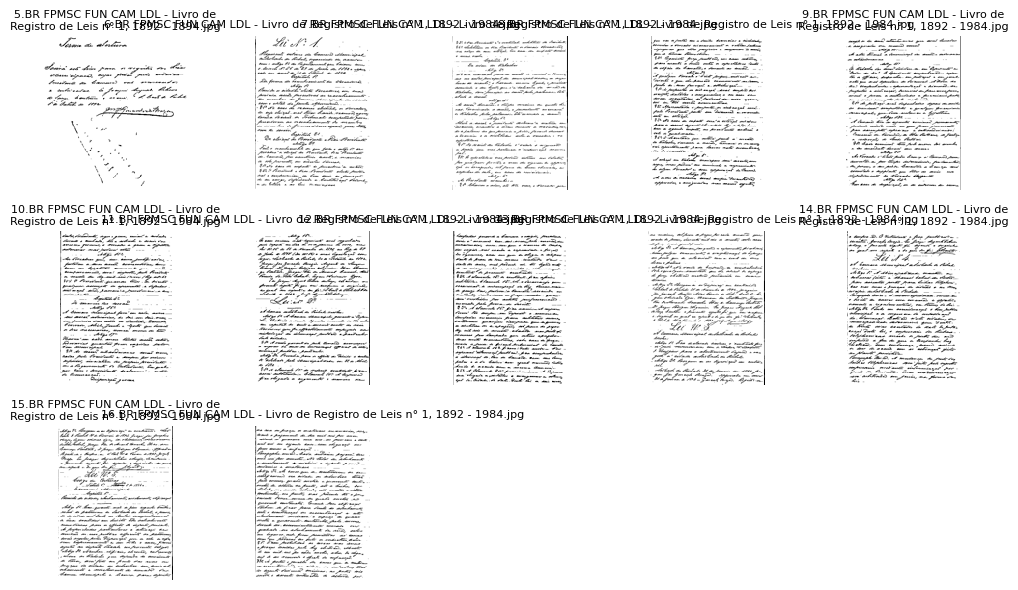

In [35]:
pasta_temporaria = Path(tempfile.mkdtemp())
gdown.download_folder(LINK_PASTA_IMAGENS, output=str(pasta_temporaria) + os.sep, use_cookies=False)
PASTA_IMAGENS = next(pasta_temporaria.iterdir())
NOME_PASTA_DRIVE = PASTA_IMAGENS.name
imagens = [p for p in PASTA_IMAGENS.iterdir()
           if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}]
imagens.sort(key=lambda p: [int(t) if t.isdigit() else t.casefold() for t in re.split(r"(\d+)", p.name)])
if not imagens:
    raise FileNotFoundError("Nenhuma imagem encontrada na pasta.")

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
ARQUIVO_RESULTADOS = PASTA_SAIDA / "-".join(f"{NOME_PASTA_DRIVE}-{CONFIG_MODELO['modelo'].split('/')[-1]}.json".lower().split())
if ARQUIVO_RESULTADOS.exists():
    raise FileExistsError(f"O JSON já existe: {ARQUIVO_RESULTADOS}")
print(f"Imagens: {len(imagens)}")
print(f"Saída: {ARQUIVO_RESULTADOS}")

linhas = (len(imagens) + 4) // 5
fig, eixos = plt.subplots(linhas, 5, figsize=(10, 2 * linhas), squeeze=False)
for eixo, imagem in zip(eixos.flat, imagens):
    with Image.open(imagem) as miniatura:
        miniatura.thumbnail((200, 160))
        eixo.imshow(miniatura, cmap="gray", interpolation="nearest")
    eixo.set_title(imagem.name, fontsize=8, wrap=True)
for eixo in eixos.flat:
    eixo.axis("off")
plt.tight_layout()
plt.show()


## 5. Transcrever
O progresso é salvo após cada imagem.


In [36]:
PROMPT = (
    "Transcreva todo o texto presente nesta imagem, preservando a grafia original. "
    "Marque trechos ilegíveis como [ilegível]. Não utilize quebras de linha. "
    "Retorne apenas a transcrição, sem introdução, explicações ou avaliação."
)
payload = {"model": CONFIG_MODELO["modelo"], "max_tokens": CONFIG_MODELO["max_tokens"]}
if CONFIG_MODELO.get("esforco_raciocinio") is not None:
    payload["reasoning"] = {"effort": CONFIG_MODELO["esforco_raciocinio"]}

resultados = {
    **CONFIG_MODELO,
    "entrada": {"pasta": NOME_PASTA_DRIVE, "link_drive": LINK_PASTA_IMAGENS,
                "quantidade_imagens": len(imagens)},
    "status": "em_andamento",
    "imagens": [],
}
custo_total = 0.0
custos_nao_informados = 0
try:
    for indice, imagem in enumerate(imagens, 1):
        print(f"[{indice}/{len(imagens)}] {imagem.name}")
        mime = mimetypes.guess_type(imagem.name)[0]
        base64_imagem = base64.b64encode(imagem.read_bytes()).decode("ascii")
        payload["messages"] = [{"role": "user", "content": [
            {"type": "text", "text": PROMPT},
            {"type": "image_url", "image_url": {"url": f"data:{mime};base64,{base64_imagem}"}},
        ]}]
        resposta = requests.post(
            "https://openrouter.ai/api/v1/chat/completions",
            headers={"Authorization": f"Bearer {API_KEY}"},
            json=payload, timeout=(30, 300),
        )
        resposta.raise_for_status()
        dados = resposta.json()
        if "error" in dados:
            raise RuntimeError(dados["error"])
        custo = (dados.get("usage") or {}).get("cost")
        if custo is not None:
            custo_total += custo
            print(f"  Custo: US$ {custo:.6f} | Acumulado informado: US$ {custo_total:.6f}")
        else:
            custos_nao_informados += 1
            print("  Custo não informado pela API.")
        escolha = dados["choices"][0]
        if escolha.get("finish_reason") == "length":
            raise RuntimeError("Resposta truncada. Aumente max_tokens na CONFIG_MODELO.")
        texto = escolha["message"].get("content")
        if not isinstance(texto, str) or not texto.strip():
            raise RuntimeError("O modelo não retornou uma transcrição em texto.")
        resultados["imagens"].append({
            "arquivo": imagem.name, "caminho_relativo": imagem.name,
            "texto_transcrito": texto, "custo": custo,
        })
        ARQUIVO_RESULTADOS.write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
    resultados["status"] = "concluido"
except Exception as erro:
    resultados["erro"] = str(erro)
    print(f"Geração interrompida: {erro}")
finally:
    ARQUIVO_RESULTADOS.write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Total dos custos informados: US$ {custo_total:.6f}")
    if custos_nao_informados:
        print(f"Total parcial: {custos_nao_informados} resposta(s) sem custo informado.")
    print(f"JSON salvo: {ARQUIVO_RESULTADOS}")


[1/12] 5.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1894.jpg
  Custo: US$ 0.003370 | Acumulado informado: US$ 0.003370
[2/12] 6.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
  Custo: US$ 0.008284 | Acumulado informado: US$ 0.011654
[3/12] 7.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
  Custo: US$ 0.003420 | Acumulado informado: US$ 0.015074
[4/12] 8.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
  Custo: US$ 0.011083 | Acumulado informado: US$ 0.026158
[5/12] 9.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
  Custo: US$ 0.017539 | Acumulado informado: US$ 0.043696
[6/12] 10.BR FPMSC FUN CAM LDL - Livro de Registro de Leis n° 1, 1892 - 1984.jpg
Total dos custos informados: US$ 0.043696
JSON salvo: respostas_json\imagens-binarizadas-gemini-3.8-flash.json


KeyboardInterrupt: 

## 6. Baixar o JSON


In [ ]:
if files is not None:
    files.download(str(ARQUIVO_RESULTADOS))
else:
    print(f"JSON disponível em: {ARQUIVO_RESULTADOS.resolve()}")


JSON disponível em: C:\Users\Maicon\Desktop\8Semestre\GitHub\hackathon_ocr_historico\respostas_json\imagens-binarizadas-gemini-3.1-pro-preview.json
